In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate , cross_val_predict , GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn-2.csv')

In [3]:
print(df.shape)
print()
print(df.head())
print()
print(df.info())
print()
print(df.describe(include='all'))

(7043, 21)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        C

In [4]:
df.groupby('Churn')['tenure'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


In [5]:
df.groupby('Churn')['MonthlyCharges'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,61.265124,64.425,18.25,118.75
Yes,74.441332,79.650,18.85,118.35


In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.groupby('Churn')['TotalCharges'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,2555.344141,1683.60,18.80,8672.45
Yes,1531.796094,703.55,18.85,8684.80


<Axes: xlabel='Churn', ylabel='TotalCharges'>

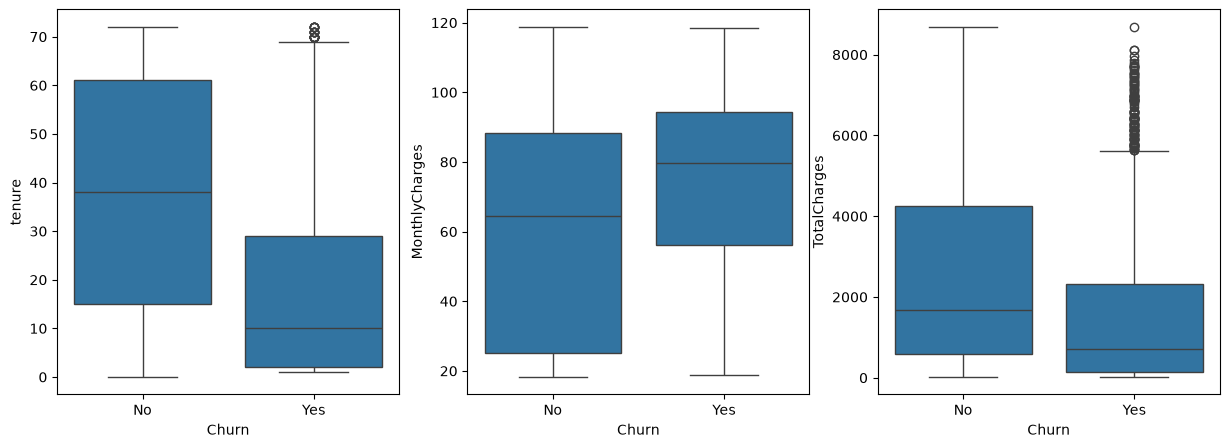

In [7]:
fig , axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0])
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1])
sns.boxplot(x='Churn', y='TotalCharges', data=df, ax=axes[2])

In [8]:
pd.crosstab(df['Contract'],df['Churn'],normalize='index')*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


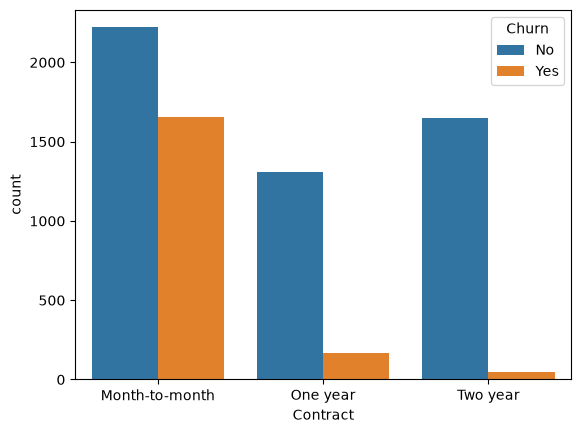

In [9]:
sns.countplot(data=df , x='Contract' , hue='Churn')
plt.show()

In [10]:
df.groupby('Churn')['tenure'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


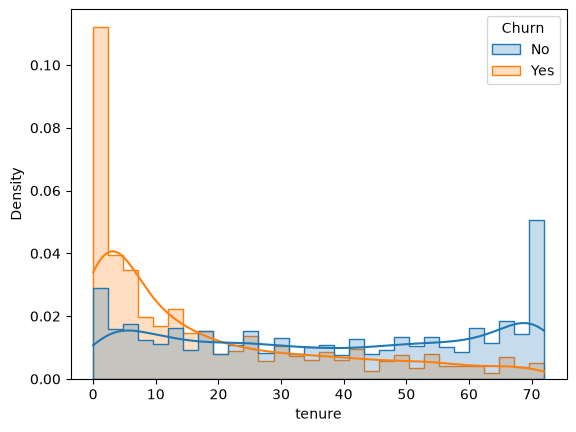

In [11]:
sns.histplot(data=df , x='tenure' , hue='Churn' , bins=30 , kde=True , element='step' , stat='density' , common_norm=False)
plt.show()

In [12]:
pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


<Axes: xlabel='PaymentMethod', ylabel='count'>

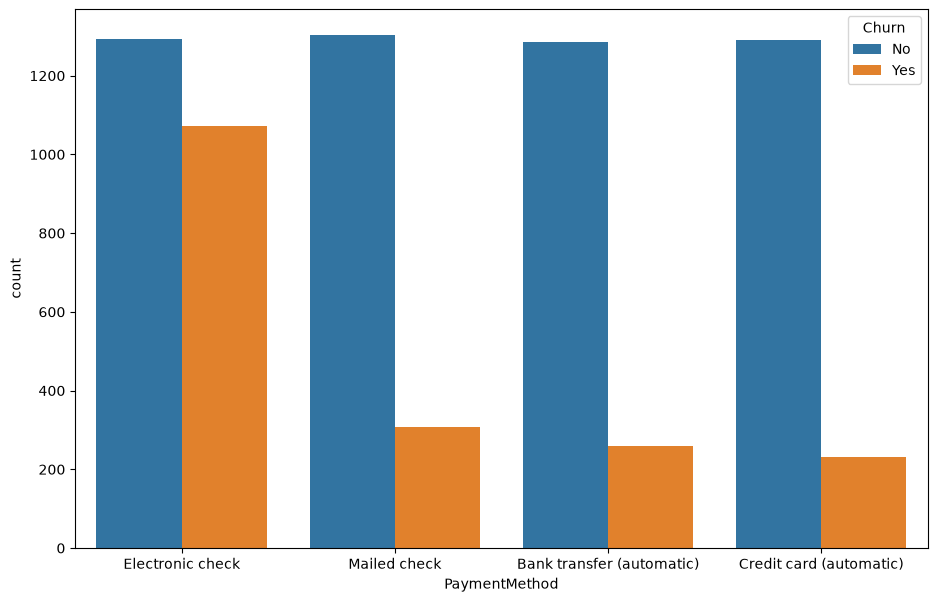

In [13]:
plt.figure(figsize=(11,7))
sns.countplot(data = df , x='PaymentMethod' , hue='Churn')

In [14]:
df.groupby('Churn')['MonthlyCharges'].agg(['mean' , 'min' , 'max'])

,mean,min,max
Churn,,,
No,61.265124,18.25,118.75
Yes,74.441332,18.85,118.35


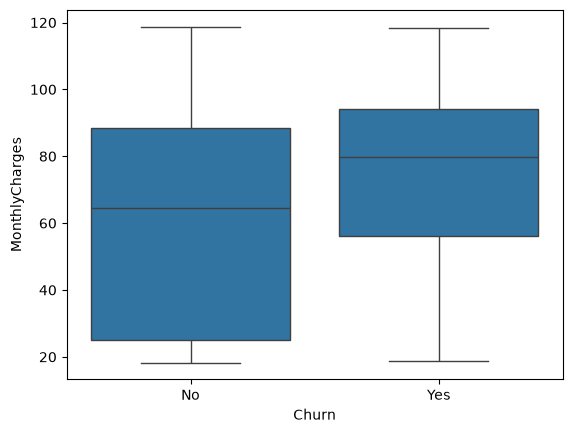

In [15]:
sns.boxplot(data=df , x="Churn" , y="MonthlyCharges")
plt.show()

In [16]:
df['ChargeGroup'] = pd.cut(
    df['MonthlyCharges'],
    bins=4
)
pd.crosstab(
    df['ChargeGroup'],
    df['Churn'],
    normalize='index'
)*100

Churn,No,Yes
ChargeGroup,,
"(18.15, 43.375]",87.677725,12.322275
"(43.375, 68.5]",78.503994,21.496006
"(68.5, 93.625]",63.187773,36.812227
"(93.625, 118.75]",66.418416,33.581584


In [17]:
pd.crosstab(
    df['PaymentMethod'],
    df['Contract'],
    normalize='index'
)*100

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


In [18]:
churn_analysis = pd.crosstab(
    index= [df["PaymentMethod"], df["Contract"]],
    columns=df["Churn"],
    normalize='index'
)*100
churn_analysis.round(2)

Churn                                        No    Yes
PaymentMethod             Contract                    
Bank transfer (automatic) Month-to-month  65.87  34.13
                          One year        90.28   9.72
                          Two year        96.63   3.37
Credit card (automatic)   Month-to-month  67.22  32.78
                          One year        89.70  10.30
                          Two year        97.76   2.24
Electronic check          Month-to-month  46.27  53.73
                          One year        81.56  18.44
                          Two year        92.26   7.74
Mailed check              Month-to-month  68.42  31.58
                          One year        93.18   6.82
                          Two year        99.21   0.79

In [19]:
customer_counts = pd.crosstab(
    index = [df["PaymentMethod"], df["Contract"]],
    columns = df["Churn"]
)
customer_counts

Churn                                      No  Yes
PaymentMethod             Contract                
Bank transfer (automatic) Month-to-month  388  201
                          One year        353   38
                          Two year        545   19
Credit card (automatic)   Month-to-month  365  178
                          One year        357   41
                          Two year        568   13
Electronic check          Month-to-month  856  994
                          One year        283   64
                          Two year        155   13
Mailed check              Month-to-month  611  282
                          One year        314   23
                          Two year        379    3

In [20]:
pd.crosstab(
    index=[df["Contract"],df["PaymentMethod"]],
    columns=df["Churn"]
)

Churn                                      No  Yes
Contract       PaymentMethod                      
Month-to-month Bank transfer (automatic)  388  201
               Credit card (automatic)    365  178
               Electronic check           856  994
               Mailed check               611  282
One year       Bank transfer (automatic)  353   38
               Credit card (automatic)    357   41
               Electronic check           283   64
               Mailed check               314   23
Two year       Bank transfer (automatic)  545   19
               Credit card (automatic)    568   13
               Electronic check           155   13
               Mailed check               379    3

In [21]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
ChargeGroup          0
dtype: int64

In [22]:
df.dtypes

customerID               str
gender                   str
SeniorCitizen          int64
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                    str
ChargeGroup         category
dtype: object

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df[df["TotalCharges"].isna()][["tenure" , "MonthlyCharges" , "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [25]:
df['TotalCharges']=df['TotalCharges'].fillna(0)

In [26]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [27]:
X = df.drop(columns=["Churn","customerID"])
y = df["Churn"]

print(X.shape)
print(y.shape)
print(X.columns)

(7043, 20)
(7043,)
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'ChargeGroup'],
      dtype='str')


In [28]:
categorical_features = X.select_dtypes(include=["object","str"]).columns
print(categorical_features)
print(len(categorical_features))

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')
15


In [29]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [30]:
x_train , x_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(5634, 20)
(1409, 20)
(5634,)
(1409,)


In [31]:
numercial_features = X.select_dtypes(
    include=["int64" , "float64"]
).columns

In [32]:
numercial_features

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [33]:
standard_scaler = StandardScaler()

In [34]:
preprocessor = ColumnTransformer(
    transformers = [
        ("cat", encoder, categorical_features),
        ("num", standard_scaler, numercial_features)
    ]
)

In [35]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

In [36]:
print(x_train_processed.shape)
print(x_test_processed.shape)
print(type(x_train_processed))

(5634, 45)
(1409, 45)
<class 'numpy.ndarray'>


In [37]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)
print(len(feature_names))

['cat__gender_Female' 'cat__gender_Male' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No internet service'
 'cat__StreamingMovies_Yes' 'cat__Contract_Month-to-month'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__PaperlessBi

In [38]:
pipeline = Pipeline(
    [
        ("preprocessing" , preprocessor),
        ("model" , LogisticRegression(max_iter=1000))
    ]
)

In [39]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes"
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes"
    ),
    "f1": make_scorer(
        f1_score, pos_label="Yes"
    ),
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [40]:
print(cv_results.keys())

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])


In [41]:
print(cv_results['test_accuracy'])

[0.79946761 0.78172138 0.80212955 0.81632653 0.81083481]


In [42]:
print(cv_results['test_f1'])

[0.58608059 0.54945055 0.58627087 0.64248705 0.5973535 ]


In [43]:
print(cv_results['test_precision'])

print(cv_results['test_recall'])

[0.64777328 0.60728745 0.65833333 0.66428571 0.68695652]
[0.53511706 0.50167224 0.52842809 0.62207358 0.52842809]


In [44]:
print(cv_results['test_roc_auc'])

[0.84791899 0.82518015 0.84191669 0.86296714 0.85302075]


In [45]:
y_proba = cross_val_predict(
    pipeline,
    x_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

In [46]:
print(y_proba.shape)
print(y_proba[:5])

(5634, 2)
[[0.6221683  0.3778317 ]
 [0.7061718  0.2938282 ]
 [0.96000455 0.03999545]
 [0.91002907 0.08997093]
 [0.63037305 0.36962695]]


In [47]:
np.unique(y_train)

array(['No', 'Yes'], dtype=object)

In [48]:
churn_proba = y_proba[:,1]

In [49]:
print(churn_proba[:10])

[0.3778317  0.2938282  0.03999545 0.08997093 0.36962695 0.0149429
 0.16684254 0.10691737 0.01955404 0.05076713]


In [50]:
thresholds = [0.2 , 0.3 , 0.4 , 0.5 , 0.6]

results = []

for threshold in thresholds :
    y_pred = np.where(
        churn_proba >= threshold,
        "Yes",
        "No"
    )
    
    results.append({
        "Threshold" : threshold,
        "Accuracy" : accuracy_score(y_train,y_pred),
        "Precision" : precision_score(
            y_train , y_pred , pos_label="Yes"
        ),
        "Recall" : recall_score(
            y_train , y_pred , pos_label="Yes"
        ),
        "F1" : f1_score(
            y_train , y_pred , pos_label="Yes"
        )
    })

In [51]:
threshold_results = pd.DataFrame(results)

In [52]:
threshold_results

,Threshold,Accuracy,Precision,Recall,F1
0,0.2,0.710863,0.475074,0.854181,0.610567
1,0.3,0.765176,0.540566,0.766555,0.634025
2,0.4,0.790380,0.593900,0.664214,0.627092
3,0.5,0.802094,0.652733,0.543144,0.592917
4,0.6,0.797125,0.711031,0.396656,0.509231


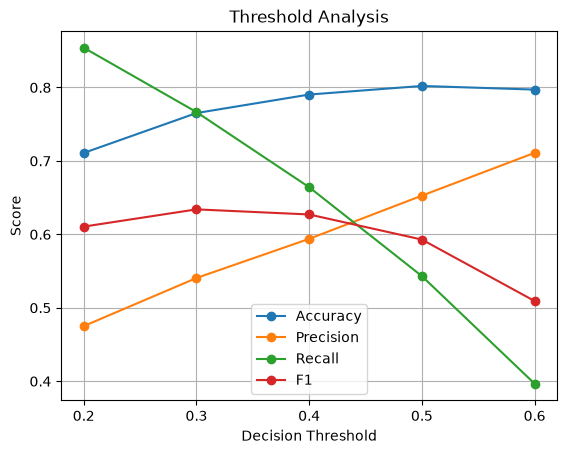

In [53]:
metrics = ["Accuracy","Precision","Recall","F1"]

for metric in metrics :
    plt.plot(
        threshold_results["Threshold"],
        threshold_results[metric],
        marker = "o",
        label = metric
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Analysis")
plt.xticks(thresholds)
plt.grid()
plt.legend()
plt.show()

In [54]:
tree_pipeline = Pipeline([
    ("Preprocessing",preprocessor),
    ("model",DecisionTreeClassifier(random_state=42))
])

In [55]:
tree_cv_results = cross_validate(
    tree_pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [56]:
tree_cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

In [57]:
tree_summary = {
    metric: tree_cv_results[f"test_{metric}"].mean() for metric in scoring
}
pd.Series(tree_summary).round(3)

accuracy     0.728
precision    0.487
recall       0.492
f1           0.489
roc_auc      0.653
dtype: float64

In [58]:
model_comparison = pd.DataFrame({
    "Logistic Regression": {
        metric: cv_results[f"test_{metric}"].mean() for metric in scoring
    },
    "Decision Tree": tree_summary
})
model_comparison.round(3)

,Logistic Regression,Decision Tree
accuracy,0.802,0.728
precision,0.653,0.487
recall,0.543,0.492
f1,0.592,0.489
roc_auc,0.846,0.653


In [59]:
rf_pipeline = Pipeline([
    ("preprocessing",preprocessor) ,
    ("model",RandomForestClassifier(random_state=42))
])

In [60]:
rf_cv_results = cross_validate(
    rf_pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [61]:
rf_cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

In [62]:
rf_summary = {
    metric: rf_cv_results[f"test_{metric}"].mean() for metric in scoring
}
pd.Series(tree_summary).round(3)

accuracy     0.728
precision    0.487
recall       0.492
f1           0.489
roc_auc      0.653
dtype: float64

In [63]:
model_comparison = pd.DataFrame(
    {
        "Logistic Regression": {
        metric: cv_results[f"test_{metric}"].mean() for metric in scoring
    },
    "Decision Tree" : tree_summary,
    "Random Forest" : rf_summary
     
     
    }
)

model_comparison.round(3)

,Logistic Regression,Decision Tree,Random Forest
accuracy,0.802,0.728,0.785
precision,0.653,0.487,0.626
recall,0.543,0.492,0.478
f1,0.592,0.489,0.542
roc_auc,0.846,0.653,0.820


In [64]:
cv_results = cross_validate(
    pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True
)

In [65]:
cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'train_accuracy', 'test_precision', 'train_precision', 'test_recall', 'train_recall', 'test_f1', 'train_f1', 'test_roc_auc', 'train_roc_auc'])

In [66]:
accuracy_comparison = {
    "Train accuracy" : cv_results["train_accuracy"].mean(),
    "Validation accuracy" : cv_results["test_accuracy"].mean()
}
pd.Series(accuracy_comparison).round(3)

Train accuracy         0.806
Validation accuracy    0.802
dtype: float64

In [71]:
metrics = list(scoring.keys())

performance_comparison = pd.DataFrame({
    "Train" : [
        cv_results[f"train_{metric}"].mean() for metric in metrics
    ],
     "Validation" : [
            cv_results[f"test_{metric}"].mean() for metric in metrics
        ],
}, index=metrics)

performance_comparison["Gap"] = (
    performance_comparison["Train"] - performance_comparison["Validation"]
)
performance_comparison.round(3)

,Train,Validation,Gap
accuracy,0.806,0.802,0.004
precision,0.662,0.653,0.009
recall,0.553,0.543,0.010
f1,0.602,0.592,0.010
roc_auc,0.850,0.846,0.003


In [75]:
param_grid = {
    "model__C" : [0.01,0.1,1,10,100]
}

f1_scorer = make_scorer(f1_score , pos_label="Yes")

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1
)

In [76]:
grid_search.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...pos_label=Yes)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the 

In [77]:
print("Best Params" , grid_search.best_params_)
print("Best CV F1 Score" , grid_search.best_score_)

Best Params {'model__C': 10}
Best CV F1 Score 0.5975404089588198


In [78]:
c_results = pd.DataFrame({
    "c" : grid_search.cv_results_["param_model__C"],
    "Mean F1" : grid_search.cv_results_["mean_test_score"],
    "STD F1" : grid_search.cv_results_["std_test_score"]
})

c_results.sort_values("Mean F1" , ascending=False).round(4)

,c,Mean F1,STD F1
3,10.00,0.5975,0.0302
4,100.00,0.5972,0.0288
2,1.00,0.5923,0.0299
1,0.10,0.5889,0.0283
0,0.01,0.5812,0.0269


In [80]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)
y_proba = best_model.predict_proba(x_test)[:, 1]

print("Accuracy: " , accuracy_score(y_test,y_pred))
print("Precision: " , precision_score(y_test , y_pred , pos_label="Yes"))
print("Recall : " , recall_score(y_test , y_pred , pos_label="Yes"))
print("F1: " , f1_score(y_test , y_pred , pos_label="Yes"))
print("ROC-AUC: " , roc_auc_score(y_test,y_proba))

Accuracy:  0.8048261178140526
Precision:  0.6551724137931034
Recall :  0.5588235294117647
F1:  0.6031746031746031
ROC-AUC:  0.8412384716732543
